# Set 6: EDA + Random Forest (optimised)

**Q1 → Exp 1A / 1B / 2** · **Q2 → Exp 10** (Random Forest)

Datasets: Q1 asks for `Precipitation.csv`, which we don't have, so this uses **`Toyota.csv`**: it has numerical **and** text columns, which this question needs. Q2 uses `Diabetes.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Toyota.csv", index_col=0, na_values=["??", "????"])   # "??" means missing in this file
df["Doors"] = df["Doors"].replace({"three": 3, "four": 4, "five": 5}).astype(int)   # words -> numbers
print(df.shape)
df.head()

(1436, 10)


,Price,Age,KM,FuelType,HP,MetColor,Automatic,CC,Doors,Weight
0,13500,23.0,46986.0,Diesel,90.0,1.0,0,2000,3,1165
1,13750,23.0,72937.0,Diesel,90.0,1.0,0,2000,3,1165
2,13950,24.0,41711.0,Diesel,90.0,NaN,0,2000,3,1165
3,14950,26.0,48000.0,Diesel,90.0,0.0,0,2000,3,1165
4,13750,30.0,38500.0,Diesel,90.0,0.0,0,2000,3,1170


### Q1.2 Display the outlier values of numerical columns using Z-score

In [3]:
num = df.select_dtypes("number")
z = ((num - num.mean()) / num.std()).abs()      # z-score: how many std-devs each value is from its column mean
for col in num.columns:
    outliers = num[col][z[col] > 3]
    print(f"{col}: {len(outliers)} outliers ->", outliers.values[:10])

Price: 26 outliers -> [22500 22000 22750 21950 21950 22250 21950 22250 32500 31000]
Age: 0 outliers -> []
KM: 17 outliers -> [243000. 216000. 198167. 205000. 204250. 194545. 190900. 183500. 232940.
 218118.]
HP: 10 outliers -> [192. 192. 192. 192. 192. 192. 192. 192. 192. 192.]
MetColor: 0 outliers -> []
Automatic: 80 outliers -> [1 1 1 1 1 1 1 1 1 1]
CC: 0 outliers -> []
Doors: 0 outliers -> []
Weight: 30 outliers -> [1245 1245 1255 1255 1270 1255 1255 1255 1275 1245]


|z| > 3 means the value is more than 3 standard deviations from the mean, so it's an outlier.

### Q1.3 Bivariate analysis of two categorical variables (count plot)

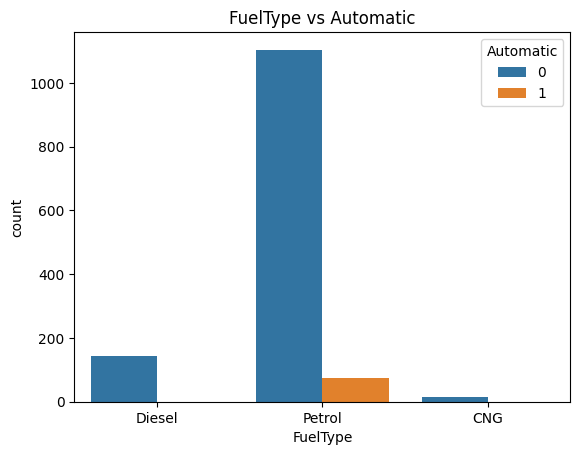

In [4]:
sns.countplot(x="FuelType", hue="Automatic", data=df)
plt.title("FuelType vs Automatic")
plt.show()

### Q1.4 Identify columns with variance < 10 and drop them

In [5]:
var = df.select_dtypes("number").var()
print(var.round(2))
low = var[var < 10].index
print("\nDropping (variance < 10):", list(low))
df = df.drop(columns=low)

Price        1.315487e+07
Age          3.455800e+02
KM           1.393755e+09
HP           2.181000e+02
MetColor     2.200000e-01
Automatic    5.000000e-02
CC           3.503726e+04
Doors        9.100000e-01
Weight       2.771090e+03
dtype: float64

Dropping (variance < 10): ['MetColor', 'Automatic', 'Doors']


### Q1.5 Label encoding of a categorical feature

In [6]:
df["FuelType"] = df["FuelType"].fillna(df["FuelType"].mode()[0])   # fill blanks first, or "nan" becomes a category
from sklearn.preprocessing import LabelEncoder

print("Before:", df["FuelType"].unique()[:6])
df["FuelType"] = LabelEncoder().fit_transform(df["FuelType"].astype(str))
print("After :", df["FuelType"].unique()[:6])

Before: ['Diesel' 'Petrol' 'CNG']
After : [1 2 0]


---
## Question 2

### Q2.1 Read, preprocess and divide into training (75%) and testing (25%)

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/Diabetes.csv")
zero_is_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]   # a 0 here is impossible = missing
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)
df = df.fillna(df.median())                           # fill with the median
X = StandardScaler().fit_transform(df.drop(columns="Outcome"))
y = df["Outcome"]
print(X.shape, y.value_counts().to_dict())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

(768, 8) {0: 500, 1: 268}
Train: (576, 8)  Test: (192, 8)


### Q2.2 Build the model and evaluate: confusion table and Accuracy

In [8]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42).fit(X_train, y_train)

In [9]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

y_pred = model.predict(X_test)
print("Confusion table:")
print(confusion_matrix(y_test, y_pred))
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall   :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F-measure:", round(f1_score(y_test, y_pred, average="macro"), 4))

Confusion table:
[[97 26]
 [22 47]]
Accuracy : 0.75
Precision: 0.7295
Recall   : 0.7349
F-measure: 0.7318


### Q2.3 Optimise (GridSearchCV), compare and plot

Best parameters: {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 100}
{'Default RF': 0.75, 'Tuned RF': 0.7552083333333334}


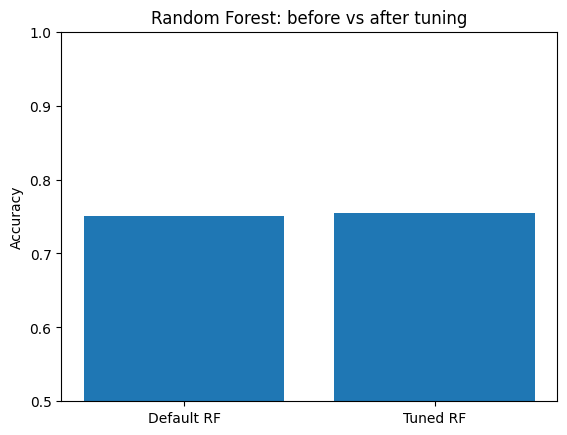

In [10]:
from sklearn.model_selection import GridSearchCV

grid = {"n_estimators": [50, 100, 200], "max_depth": [None, 4, 8], "criterion": ["gini", "entropy"]}
search = GridSearchCV(RandomForestClassifier(random_state=42), grid, cv=5, n_jobs=-1).fit(X_train, y_train)
print("Best parameters:", search.best_params_)

scores = {"Default RF": accuracy_score(y_test, y_pred), "Tuned RF": accuracy_score(y_test, search.predict(X_test))}
print(scores)
plt.bar(scores.keys(), scores.values())
plt.ylim(0.5, 1)
plt.ylabel("Accuracy")
plt.title("Random Forest: before vs after tuning")
plt.show()